#### Import Library

In [1]:
# Import library from Python Index Package (PyPI)
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

# Pengganti google.colab.patches.cv2_imshow agar notebook bisa dijalankan di Google Colab maupun lokal
def cv2_imshow(image):
    plt.figure(figsize=(10, 7.5))
    if image.ndim == 2:
        plt.imshow(image, cmap='gray', vmin=0, vmax=255)
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()

## Bagian I - Input Citra

Dataset: d:\UNAIR\Semester 7\Computer Vision\Kelompok 6_UTS\data
Jumlah citra di d:\UNAIR\Semester 7\Computer Vision\Kelompok 6_UTS\data\img: 20
['IMG_9208.jpg', 'IMG_9209.jpg', 'IMG_9210.jpg', 'IMG_9211.jpg', 'IMG_9212.jpg', 'IMG_9213.jpg', 'IMG_9214.jpg', 'IMG_9215.jpg', 'IMG_9218.jpg', 'IMG_9219.jpg', 'IMG_9222.jpg', 'IMG_9223.jpg', 'IMG_9225.jpg', 'IMG_9228.jpg', 'IMG_9229.jpg', 'IMG_9230.jpg', 'IMG_9234.jpg', 'IMG_9236.jpg', 'IMG_9240.jpg', 'IMG_9243.jpg']
Original Image:


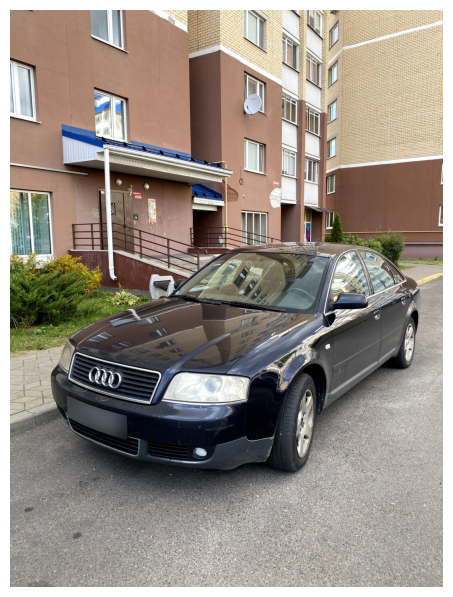


Image Dimension: 
(4032, 3024, 3)

Image Pixel Value: 
[[[112 127 159]
  [113 128 160]
  [116 131 163]
  ...
  [201 230 245]
  [168 197 212]
  [137 166 181]]

 [[114 129 161]
  [115 130 162]
  [117 132 164]
  ...
  [203 232 247]
  [168 197 212]
  [137 166 181]]

 [[114 129 161]
  [114 129 161]
  [115 130 162]
  ...
  [193 222 237]
  [163 192 207]
  [138 167 182]]

 ...

 [[147 150 154]
  [136 139 143]
  [136 139 143]
  ...
  [140 145 146]
  [149 154 155]
  [153 157 158]]

 [[129 132 136]
  [147 150 154]
  [147 150 154]
  ...
  [189 193 194]
  [194 198 199]
  [187 191 192]]

 [[135 138 142]
  [141 144 148]
  [139 142 146]
  ...
  [213 217 218]
  [215 219 220]
  [208 212 213]]]


In [2]:
# Lokasi dataset
# - Lokal : folder data/ di root project (dicari ke atas dari direktori kerja,
#           sehingga bisa dijalankan dari root project maupun dari notebooks/)
# - Google Colab (atau jika folder data/ tidak ada): dataset diunduh dari Kaggle dengan kagglehub
DATA_DIR = next((p / 'data' for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'img').is_dir()), None)
if DATA_DIR is None:
    import kagglehub
    DATA_DIR = Path(kagglehub.dataset_download('trainingdatapro/car-masks')) / 'cars'
print(f'Dataset: {DATA_DIR}')

IMG_DIR = DATA_DIR / 'img'
MASK_DIR = DATA_DIR / 'masks'

# Daftar citra yang tersedia
image_files = sorted(IMG_DIR.glob('*.jpg'))
print(f'Jumlah citra di {IMG_DIR}: {len(image_files)}')
print([f.name for f in image_files])

# Load image
image_path = IMG_DIR / 'IMG_9208.jpg'
image = cv2.imread(str(image_path))
if image is None:
    raise FileNotFoundError(f'Citra tidak ditemukan: {image_path}')

# Show image
print("Original Image:")
cv2_imshow(image)

# Image dimension
print('\nImage Dimension: ')
print(image.shape)

# Image pixel value
print('\nImage Pixel Value: ')
print(image)

Image Grayscaled:


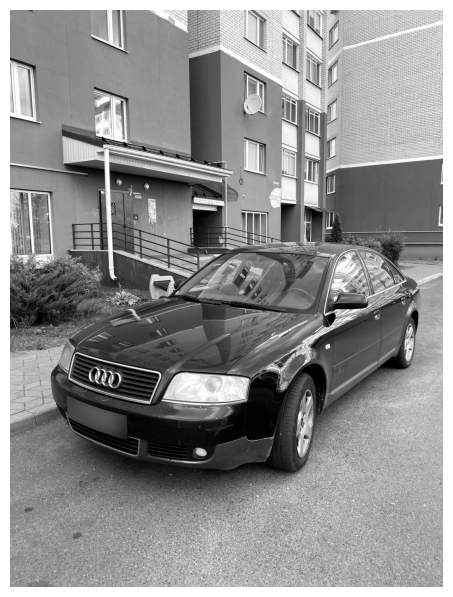


 Grayscaled Image Dimension: 
(4032, 3024)

 Grayscaled Image Pixel Value: 
[[135 136 139 ... 231 198 167]
 [137 138 140 ... 233 198 167]
 [137 137 138 ... 223 193 168]
 ...
 [151 140 140 ... 145 154 157]
 [133 151 151 ... 193 198 191]
 [139 145 143 ... 217 219 212]]


In [3]:
# Grayscale image
image_grayscale = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Show grayscaled image
print("Image Grayscaled:")
cv2_imshow(image_grayscale)

# Show grayscaled image dimension
print('\n Grayscaled Image Dimension: ')
print(image_grayscale.shape)

# Show grayscaled image pixel value
print('\n Grayscaled Image Pixel Value: ')
print(image_grayscale)

## Bagian II - IMAGE ENHANCEMENT

In [4]:
# Import library tambahan untuk Bagian II
import numpy as np
from skimage.metrics import structural_similarity as ssim

Image Enhancement - Contrast Stretching

Image Contrast Stretching:


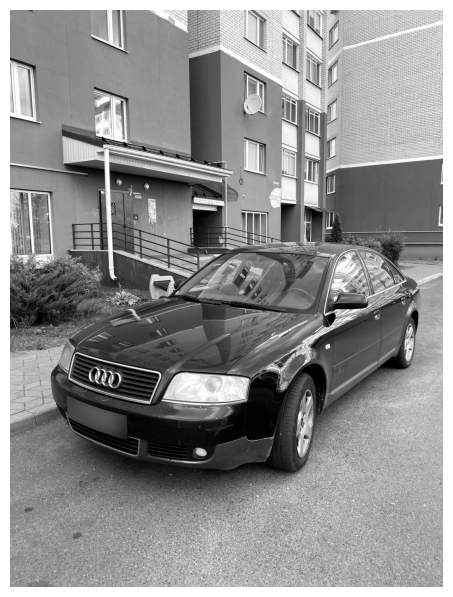


Contrast Stretched Image Dimension: 
(4032, 3024)

Contrast Stretched Image Pixel Value: 
[[135 136 139 ... 231 198 167]
 [137 138 140 ... 233 198 167]
 [137 137 138 ... 223 193 168]
 ...
 [151 140 140 ... 145 154 157]
 [133 151 151 ... 193 198 191]
 [139 145 143 ... 217 219 212]]


In [5]:
# Contrast stretching (min-max normalization ke rentang 0-255)
image_contrast_stretching = cv2.normalize(image_grayscale, None, 0, 255, cv2.NORM_MINMAX)

# Show contrast stretched image
print("Image Contrast Stretching:")
cv2_imshow(image_contrast_stretching)

# Show contrast stretched image dimension
print('\nContrast Stretched Image Dimension: ')
print(image_contrast_stretching.shape)

# Show contrast stretched image pixel value
print('\nContrast Stretched Image Pixel Value: ')
print(image_contrast_stretching)

Image Enhancement - Histogram Equalization

Image Histogram Equalized:


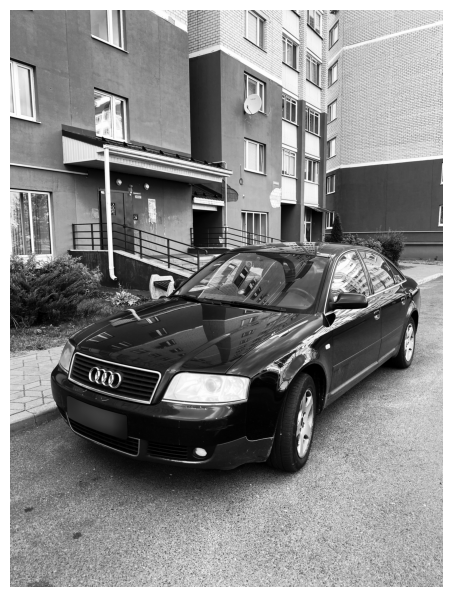


Histogram Equalized Image Dimension: 
(4032, 3024)

Histogram Equalized Image Pixel Value: 
[[115 117 123 ... 239 215 181]
 [119 121 126 ... 240 215 181]
 [119 119 121 ... 234 210 183]
 ...
 [154 126 126 ... 138 160 166]
 [112 154 154 ... 210 215 208]
 [123 138 133 ... 229 231 226]]


In [6]:
# Histogram equalization (global)
image_histogram_equalized = cv2.equalizeHist(image_grayscale)

# Show histogram equalized image
print("Image Histogram Equalized:")
cv2_imshow(image_histogram_equalized)

# Show histogram equalized image dimension
print('\nHistogram Equalized Image Dimension: ')
print(image_histogram_equalized.shape)

# Show histogram equalized image pixel value
print('\nHistogram Equalized Image Pixel Value: ')
print(image_histogram_equalized)

Image Enhancement - CLAHE

Image CLAHE:


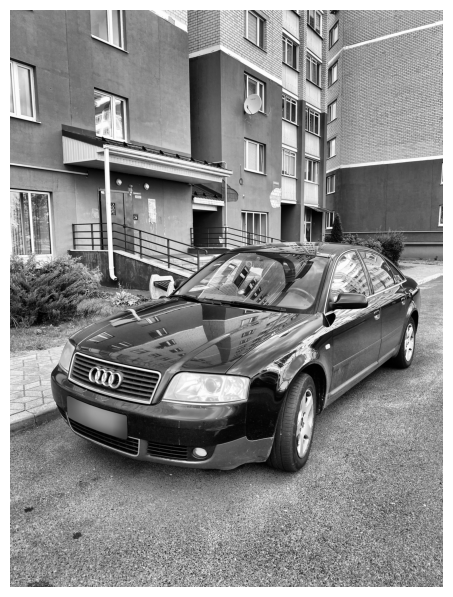


CLAHE Image Dimension: 
(4032, 3024)

CLAHE Image Pixel Value: 
[[119 122 130 ... 215 147 107]
 [125 127 133 ... 220 147 107]
 [125 125 127 ... 197 140 108]
 ...
 [148 121 121 ...  92 114 121]
 [104 148 148 ... 205 214 201]
 [119 133 128 ... 234 236 230]]


In [7]:
# CLAHE (Contrast Limited Adaptive Histogram Equalization)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
image_clahe = clahe.apply(image_grayscale)

# Show CLAHE image
print("Image CLAHE:")
cv2_imshow(image_clahe)

# Show CLAHE image dimension
print('\nCLAHE Image Dimension: ')
print(image_clahe.shape)

# Show CLAHE image pixel value
print('\nCLAHE Image Pixel Value: ')
print(image_clahe)

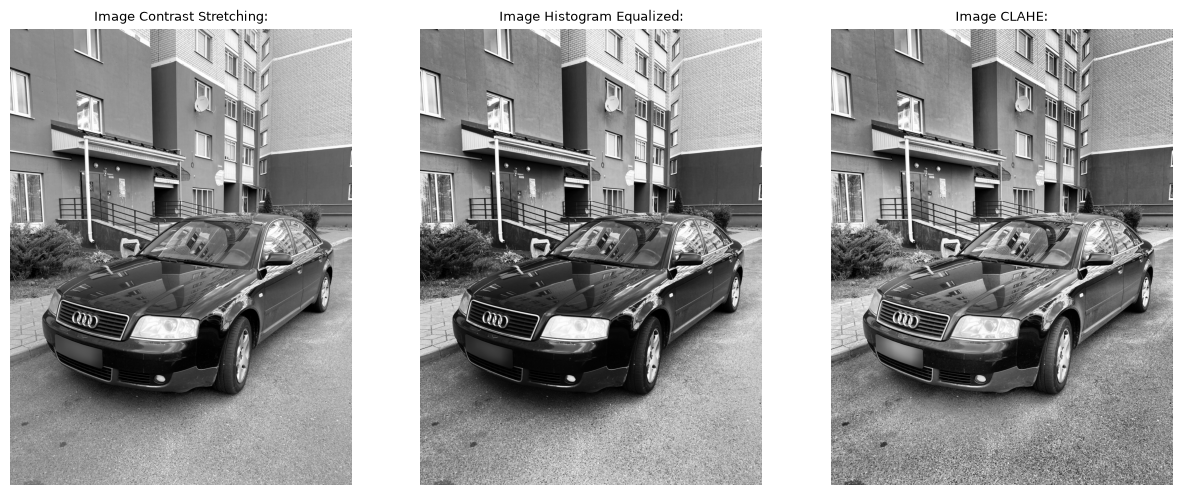

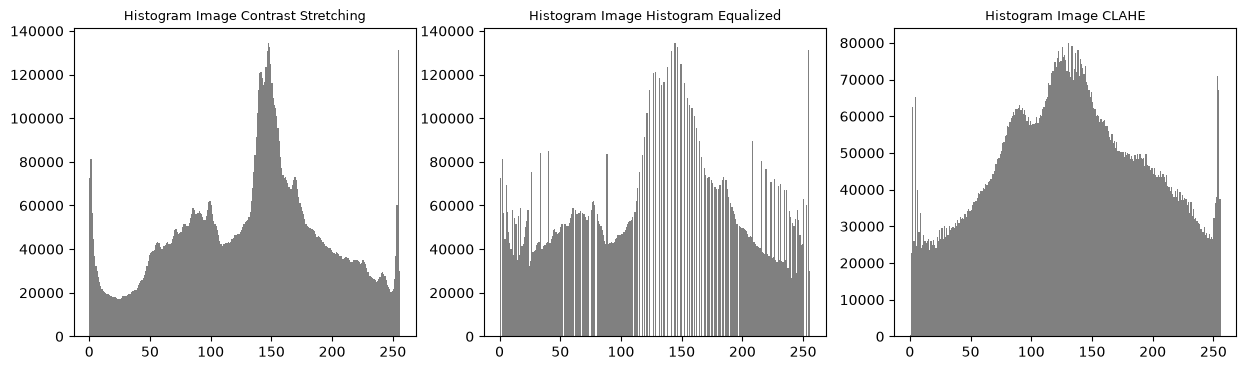

In [8]:
# Perbandingan hasil enhancement
enhanced_images = [image_contrast_stretching, image_histogram_equalized, image_clahe]
enhanced_titles = ['Image Contrast Stretching:', 'Image Histogram Equalized:', 'Image CLAHE:']

plt.figure(figsize=(15, 6))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(enhanced_images[i], cmap='gray')
    plt.title(enhanced_titles[i], fontsize=9)
    plt.axis('off')
plt.show()

# Perbandingan histogram
plt.figure(figsize=(15, 4))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.hist(enhanced_images[i].ravel(), bins=256, range=(0, 256), color='gray')
    plt.title('Histogram ' + enhanced_titles[i].replace(':', ''), fontsize=9)
plt.show()

Median Filtering

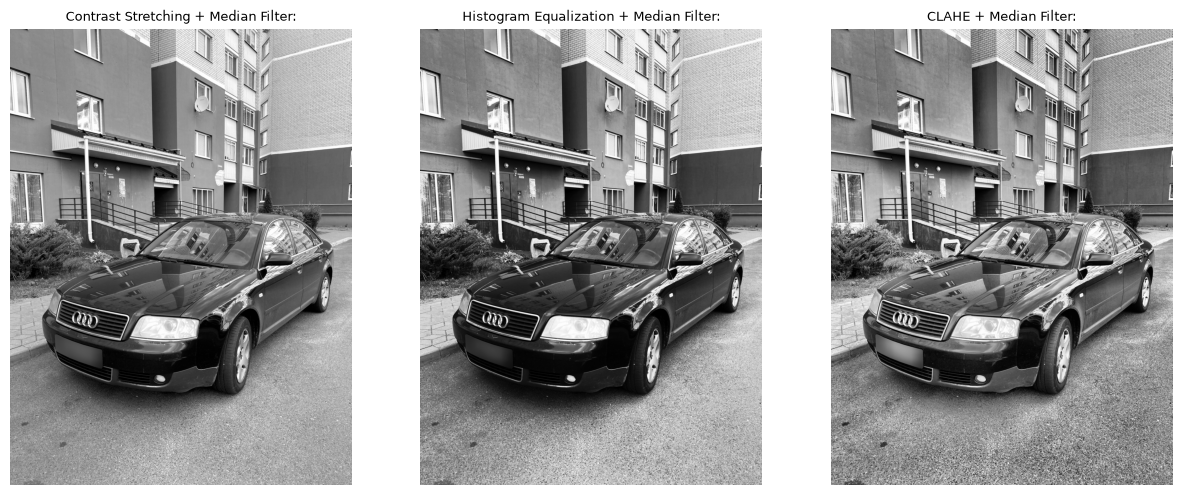


Median Filtered Image Dimension: 
(4032, 3024)


In [9]:
# Median filtering (kernel 3x3) pada setiap hasil enhancement
kernel_size = 3
image_cs_median = cv2.medianBlur(image_contrast_stretching, kernel_size)
image_he_median = cv2.medianBlur(image_histogram_equalized, kernel_size)
image_clahe_median = cv2.medianBlur(image_clahe, kernel_size)

# Show median filtered images
median_images = [image_cs_median, image_he_median, image_clahe_median]
median_titles = ['Contrast Stretching + Median Filter:',
                 'Histogram Equalization + Median Filter:',
                 'CLAHE + Median Filter:']

plt.figure(figsize=(15, 6))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(median_images[i], cmap='gray')
    plt.title(median_titles[i], fontsize=9)
    plt.axis('off')
plt.show()

# Show median filtered image dimension
print('\nMedian Filtered Image Dimension: ')
print(image_cs_median.shape)

Evaluasi MSE, PSNR, dan SSIM

In [10]:
# Fungsi Mean Square Error
def calculate_mse(image_original, image_processed):
    f1 = image_original.astype(np.float64)
    f2 = image_processed.astype(np.float64)
    return np.mean((f1 - f2) ** 2)

# Fungsi Peak Signal to Noise Ratio
def calculate_psnr(image_original, image_processed):
    mse = calculate_mse(image_original, image_processed)
    if mse == 0:
        return float('inf')  # citra identik
    return 20 * np.log10(255.0 / np.sqrt(mse))

# Fungsi Structural Similarity Index Measure
def calculate_ssim(image_original, image_processed):
    return ssim(image_original, image_processed, data_range=255)

# Fungsi untuk menampilkan hasil evaluasi
def show_evaluation(name, image_original, image_processed):
    print(f'MSE Image {name}:')
    print(f'{calculate_mse(image_original, image_processed):.10f}')
    print(f'\nPSNR Image {name}:')
    print(f'{calculate_psnr(image_original, image_processed):.10f} dB')
    print(f'\nSSIM Image {name}:')
    print(f'{calculate_ssim(image_original, image_processed):.10f}')
    print('\n' + '-' * 50 + '\n')

In [11]:
# Evaluasi tanpa median filtering (pembanding: citra grayscale)
show_evaluation('Contrast Stretching', image_grayscale, image_contrast_stretching)
show_evaluation('Histogram Equalization', image_grayscale, image_histogram_equalized)
show_evaluation('CLAHE', image_grayscale, image_clahe)

MSE Image Contrast Stretching:
0.0000000000

PSNR Image Contrast Stretching:
inf dB

SSIM Image Contrast Stretching:
1.0000000000

--------------------------------------------------

MSE Image Histogram Equalization:
290.1837086542

PSNR Image Histogram Equalization:
23.5040733402 dB

SSIM Image Histogram Equalization:
0.9196814083

--------------------------------------------------

MSE Image CLAHE:
723.5099272782

PSNR Image CLAHE:
19.5363586642 dB

SSIM Image CLAHE:
0.8760928091

--------------------------------------------------



In [12]:
# Evaluasi dengan median filtering (pembanding: citra grayscale)
show_evaluation('Contrast Stretching with Median Filtering', image_grayscale, image_cs_median)
show_evaluation('Histogram Equalization with Median Filtering', image_grayscale, image_he_median)
show_evaluation('CLAHE with Median Filtering', image_grayscale, image_clahe_median)

MSE Image Contrast Stretching with Median Filtering:
63.9183556187

PSNR Image Contrast Stretching with Median Filtering:
30.0745476720 dB

SSIM Image Contrast Stretching with Median Filtering:
0.9198904847

--------------------------------------------------

MSE Image Histogram Equalization with Median Filtering:
333.8536327436

PSNR Image Histogram Equalization with Median Filtering:
22.8952425461 dB

SSIM Image Histogram Equalization with Median Filtering:
0.8719012885

--------------------------------------------------

MSE Image CLAHE with Median Filtering:
711.0394651157

PSNR Image CLAHE with Median Filtering:
19.6118665464 dB

SSIM Image CLAHE with Median Filtering:
0.8612526185

--------------------------------------------------



In [13]:
# Tabel ringkasan evaluasi
import pandas as pd

results = []
for name, img in zip(['Contrast Stretching', 'Histogram Equalization', 'CLAHE',
                      'Contrast Stretching + Median', 'Histogram Equalization + Median', 'CLAHE + Median'],
                     enhanced_images + median_images):
    results.append({
        'Metode': name,
        'MSE': calculate_mse(image_grayscale, img),
        'PSNR (dB)': calculate_psnr(image_grayscale, img),
        'SSIM': calculate_ssim(image_grayscale, img)
    })

df_eval = pd.DataFrame(results)
df_eval

,Metode,MSE,PSNR (dB),SSIM
0,Contrast Stretching,0.000000,inf,1.000000
1,Histogram Equalization,290.183709,23.504073,0.919681
2,CLAHE,723.509927,19.536359,0.876093
3,Contrast Stretching + Median,63.918356,30.074548,0.919890
4,Histogram Equalization + Median,333.853633,22.895243,0.871901
5,CLAHE + Median,711.039465,19.611867,0.861253


## Bagian III - SEGMENTASI CITRA

Segmentasi dilakukan pada citra hasil preprocessing (enhancement + median filtering) dengan dua metode thresholding:

1. **Otsu Thresholding**
2. **Adaptive Thresholding (Local Mean)**

In [14]:
# Citra input segmentasi: hasil enhancement + median filtering
segmentation_inputs = [image_cs_median, image_he_median, image_clahe_median]
segmentation_names = ['Contrast Stretching + Median',
                      'Histogram Equalization + Median',
                      'CLAHE + Median']

Segmentasi - Otsu Thresholding

Otsu Threshold Contrast Stretching + Median: 120
Otsu Threshold Histogram Equalization + Median: 123
Otsu Threshold CLAHE + Median: 130


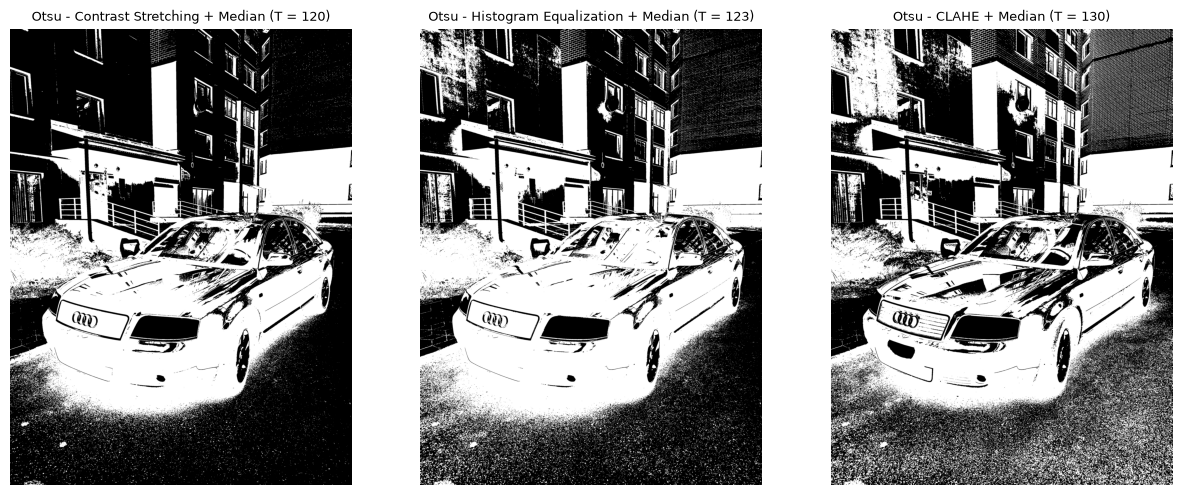

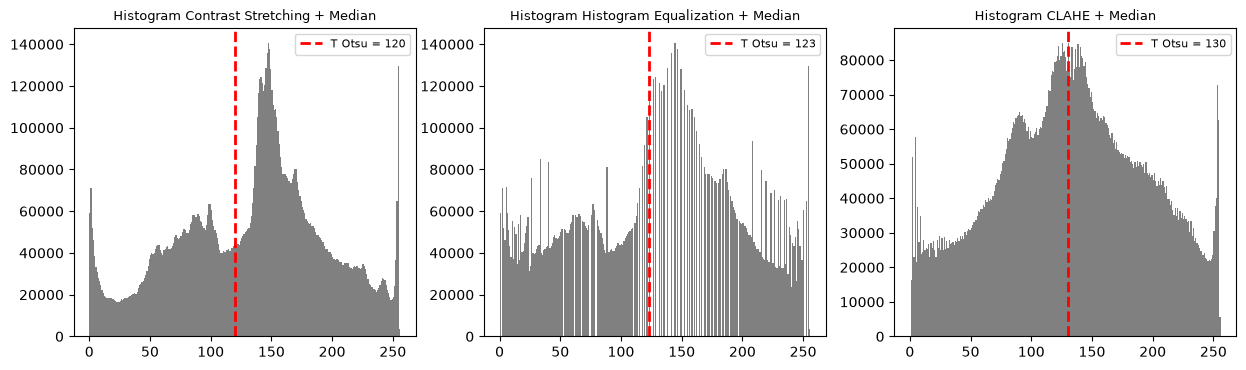

In [15]:
# Otsu thresholding (nilai threshold dihitung otomatis dari histogram)
otsu_thresholds = []
otsu_images = []
for img in segmentation_inputs:
    threshold, image_otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    otsu_thresholds.append(threshold)
    otsu_images.append(image_otsu)

# Show Otsu threshold value
for name, threshold in zip(segmentation_names, otsu_thresholds):
    print(f'Otsu Threshold {name}: {threshold:.0f}')

# Show Otsu segmented images
plt.figure(figsize=(15, 6))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(otsu_images[i], cmap='gray')
    plt.title(f'Otsu - {segmentation_names[i]} (T = {otsu_thresholds[i]:.0f})', fontsize=9)
    plt.axis('off')
plt.show()

# Histogram dengan garis threshold Otsu
plt.figure(figsize=(15, 4))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.hist(segmentation_inputs[i].ravel(), bins=256, range=(0, 256), color='gray')
    plt.axvline(otsu_thresholds[i], color='red', linestyle='--', linewidth=2, label=f'T Otsu = {otsu_thresholds[i]:.0f}')
    plt.title('Histogram ' + segmentation_names[i], fontsize=9)
    plt.legend(fontsize=8)
plt.show()

Segmentasi - Adaptive Thresholding (Local Mean)

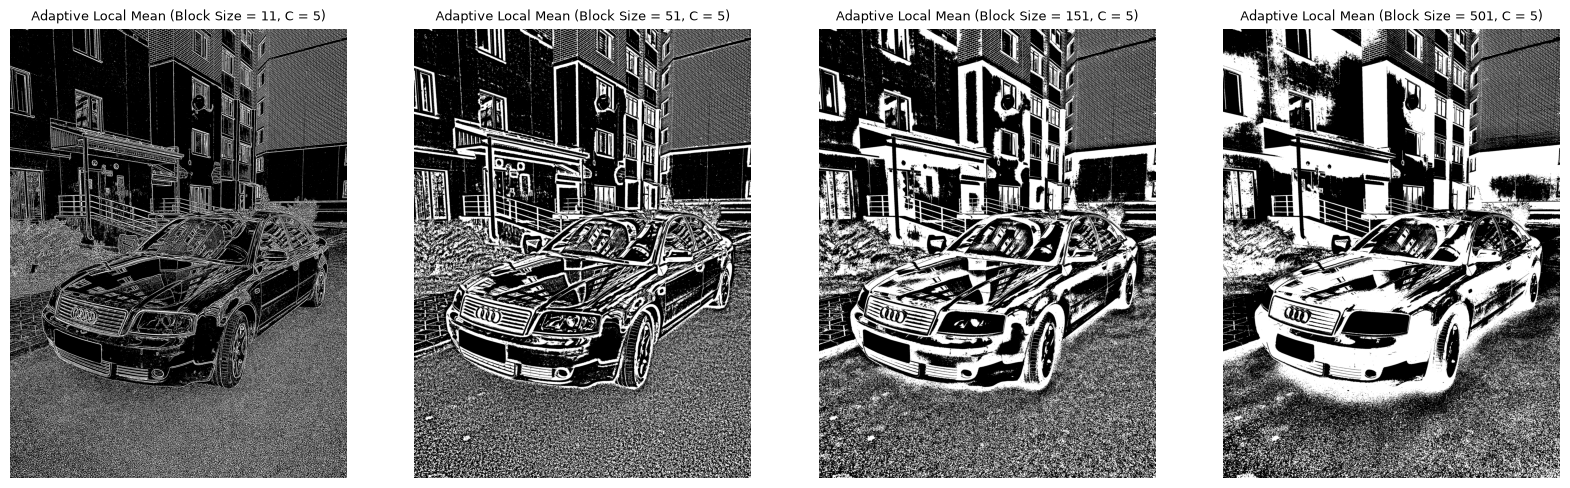

In [16]:
# Pengaruh ukuran blok pada adaptive local mean (citra Contrast Stretching + Median)
block_sizes = [11, 51, 151, 501]

plt.figure(figsize=(20, 7))
for i, bs in enumerate(block_sizes):
    image_adaptive_bs = cv2.adaptiveThreshold(image_cs_median, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                                              cv2.THRESH_BINARY_INV, bs, 5)
    plt.subplot(1, 4, i + 1)
    plt.imshow(image_adaptive_bs, cmap='gray')
    plt.title(f'Adaptive Local Mean (Block Size = {bs}, C = 5)', fontsize=9)
    plt.axis('off')
plt.show()

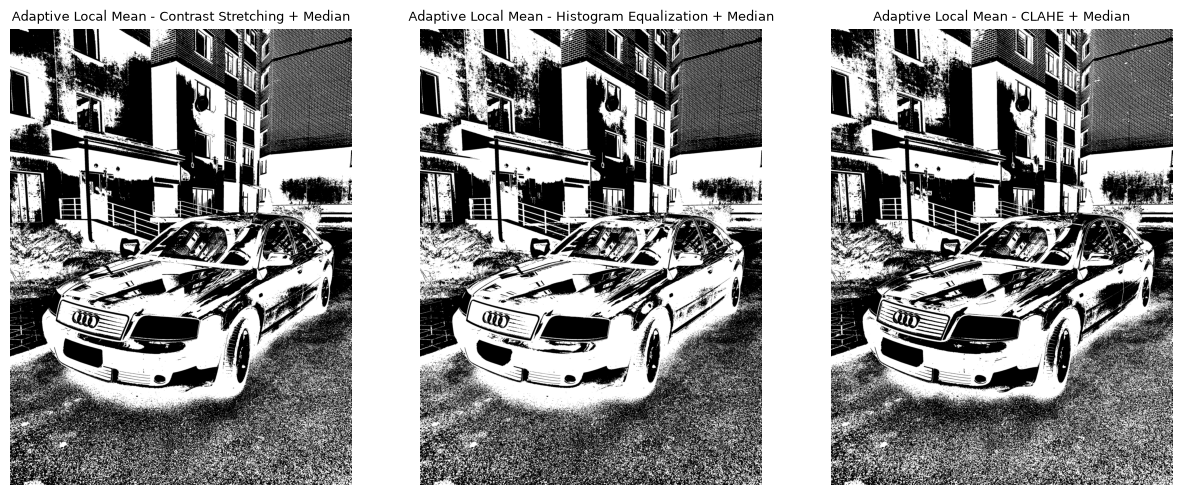


Adaptive Segmented Image Dimension: 
(4032, 3024)

Adaptive Segmented Image Pixel Value: 
[[  0   0   0 ...   0   0 255]
 [  0   0   0 ...   0   0 255]
 [  0   0   0 ...   0   0 255]
 ...
 [  0   0   0 ... 255 255 255]
 [  0   0   0 ...   0   0   0]
 [  0   0   0 ...   0   0   0]]


In [17]:
# Adaptive thresholding - local mean
block_size = 501  # ukuran blok (harus ganjil)
C = 5             # konstanta pengurang rata-rata lokal

adaptive_images = []
for img in segmentation_inputs:
    image_adaptive = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                                           cv2.THRESH_BINARY_INV, block_size, C)
    adaptive_images.append(image_adaptive)

# Show adaptive local mean segmented images
plt.figure(figsize=(15, 6))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(adaptive_images[i], cmap='gray')
    plt.title(f'Adaptive Local Mean - {segmentation_names[i]}', fontsize=9)
    plt.axis('off')
plt.show()

# Show adaptive segmented image dimension
print('\nAdaptive Segmented Image Dimension: ')
print(adaptive_images[0].shape)

# Show adaptive segmented image pixel value
print('\nAdaptive Segmented Image Pixel Value: ')
print(adaptive_images[0])

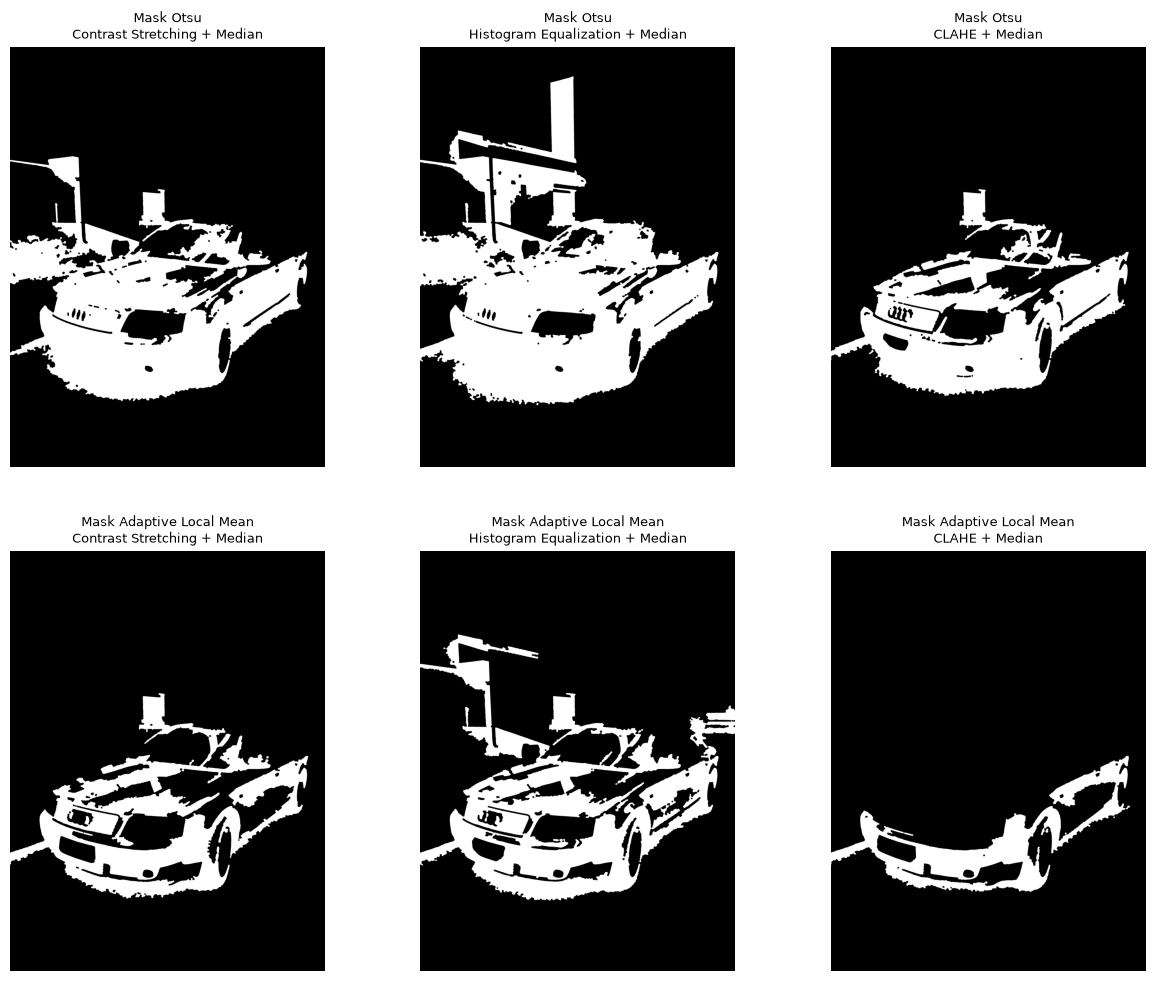

In [18]:
# Kernel morfologi berbentuk elips 15x15
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))

# Fungsi opening lalu closing
def morphology_cleaning(image_binary):
    image_opening = cv2.morphologyEx(image_binary, cv2.MORPH_OPEN, kernel)
    return cv2.morphologyEx(image_opening, cv2.MORPH_CLOSE, kernel)

# Fungsi mengambil komponen terhubung terbesar (selain background)
def largest_component(image_binary):
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(image_binary, connectivity=8)
    if num_labels <= 1:
        return image_binary  # tidak ada foreground
    largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    return np.where(labels == largest_label, 255, 0).astype(np.uint8)

# Terapkan post-processing pada setiap hasil segmentasi
segmentation_results = {'Otsu': otsu_images, 'Adaptive Local Mean': adaptive_images}
object_masks = {}
for method, images in segmentation_results.items():
    object_masks[method] = [largest_component(morphology_cleaning(img)) for img in images]

# Show object masks
plt.figure(figsize=(15, 12))
for row, method in enumerate(object_masks):
    for i in range(3):
        plt.subplot(2, 3, row * 3 + i + 1)
        plt.imshow(object_masks[method][i], cmap='gray')
        plt.title(f'Mask {method}\n{segmentation_names[i]}', fontsize=9)
        plt.axis('off')
plt.show()

Hasil Segmentasi Objek

In [ ]:
# Terapkan mask ke citra asli (piksel di luar objek menjadi hitam)
plt.figure(figsize=(15, 12))
for row, method in enumerate(object_masks):
    for i in range(3):
        image_segmented = cv2.bitwise_and(image, image, mask=object_masks[method][i])
        plt.subplot(2, 3, row * 3 + i + 1)
        plt.imshow(cv2.cvtColor(image_segmented, cv2.COLOR_BGR2RGB))
        plt.title(f'Segmentasi {method}\n{segmentation_names[i]}', fontsize=9)
        plt.axis('off')
plt.show()

In [ ]:
# Tabel ringkasan segmentasi
seg_results = []
for method, images in segmentation_results.items():
    for i, name in enumerate(segmentation_names):
        if method == 'Otsu':
            parameter = f'T = {otsu_thresholds[i]:.0f}'
        else:
            parameter = f'Block Size = {block_size}, C = {C}'
        seg_results.append({
            'Metode Segmentasi': method,
            'Citra Input': name,
            'Parameter': parameter,
            'Foreground Thresholding (%)': np.mean(images[i] == 255) * 100,
            'Objek Akhir (%)': np.mean(object_masks[method][i] == 255) * 100
        })

df_seg = pd.DataFrame(seg_results)
df_seg

,Metode Segmentasi,Citra Input,Parameter,Foreground Thresholding (%),Objek Akhir (%)
0,Otsu,Contrast Stretching + Median,T = 120,38.022039,23.239054
1,Otsu,Histogram Equalization + Median,T = 123,47.599019,31.028401
2,Otsu,CLAHE + Median,T = 130,49.476854,16.869713
3,Adaptive Local Mean,Contrast Stretching + Median,"Block Size = 501, C = 5",46.087107,13.178533
4,Adaptive Local Mean,Histogram Equalization + Median,"Block Size = 501, C = 5",49.216913,18.674185
5,Adaptive Local Mean,CLAHE + Median,"Block Size = 501, C = 5",47.092301,6.829606


Analisis Hasil Segmentasi

- **Otsu Thresholding** menghasilkan threshold T = 120 (Contrast Stretching + Median), T = 123 (Histogram Equalization + Median), dan T = 130 (CLAHE + Median). Karena mobil lebih gelap dari aspal, bodi mobil tersegmentasi sebagai satu region yang cukup utuh. Namun, threshold global juga meloloskan objek lain yang sama gelapnya (bagian bangunan, tangga, semak, dan bayangan di bawah mobil), sehingga setelah diambil komponen terbesar masih ada latar yang menempel pada mobil.
- **Adaptive Local Mean** sangat dipengaruhi ukuran blok. Dengan blok kecil (11 dan 51) hasilnya menyerupai deteksi tepi, karena pada region yang seragam nilai piksel hampir sama dengan rata-rata lokalnya. Dengan blok 501 region mulai terbentuk, tetapi bodi mobil yang gelap dan memantulkan cahaya (kap dan kaca) terpecah menjadi beberapa bagian, sehingga mask objek akhir kurang utuh dibanding Otsu.
- **Pengaruh preprocessing**: CLAHE meningkatkan kontras lokal sehingga pantulan pada bodi mobil menjadi lebih terang dan memecah objek (mask akhir paling kecil pada kedua metode). Histogram Equalization membuat lebih banyak bagian bangunan ikut tersegmentasi dan menempel pada mobil. Contrast Stretching + Median memberikan keseimbangan terbaik: bodi mobil paling utuh dengan latar yang menempel lebih sedikit.
- Persentase **Objek Akhir** pada tabel bukan ukuran akurasi. Nilai yang lebih besar dapat berarti lebih banyak latar yang ikut tersegmentasi (misalnya Otsu - Histogram Equalization + Median).

**Kesimpulan:** Untuk citra ini, kombinasi **Contrast Stretching + Median Filtering + Otsu Thresholding** yang diikuti operasi morfologi memberikan hasil segmentasi objek mobil terbaik. Adaptive local mean lebih cocok untuk menonjolkan tepi/detail lokal atau untuk citra dengan pencahayaan tidak merata, bukan untuk memisahkan objek gelap yang luas seperti mobil pada citra ini.